In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the practice dataset
df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
# Select numerical columns
numerical_df = df.select_dtypes(include="number")

print("Numerical features:")
print(numerical_df.columns.tolist())

print("\nSummary statistics:")
display(numerical_df.describe().round(2))

Numerical features:
['total_bill', 'tip', 'size']

Summary statistics:


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


## 1. Normal Distribution

A normal distribution is a bell-shaped, symmetrical distribution in which most observations are concentrated around the mean. In a perfectly normal distribution, the mean, median, and mode are equal. Values become less frequent as we move away from the center.

A normal distribution can be examined using a histogram and a density curve.

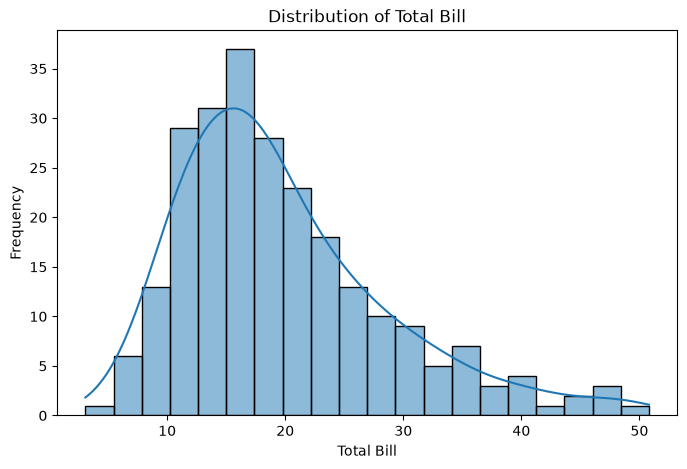

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="total_bill",
    kde=True,
    bins=20
)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.show()

## 2. Uniform Distribution

A uniform distribution is a probability distribution in which values have equal probability over a specified interval. Its continuous form appears approximately flat across the interval. Unlike a normal distribution, it does not have a central peak.

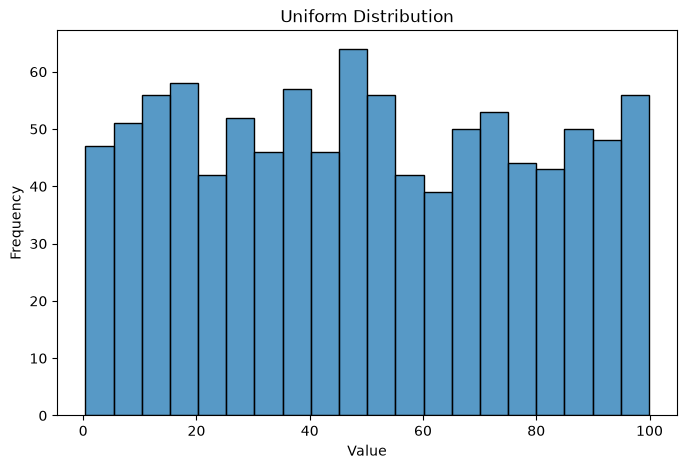

In [4]:
# Generate sample uniform data
uniform_data = np.random.uniform(0, 100, 1000)

plt.figure(figsize=(8, 5))
sns.histplot(uniform_data, bins=20, kde=False)

plt.title("Uniform Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

## 3. Skewness

Skewness measures the asymmetry of a distribution.

- **Symmetric:** Skewness is approximately zero.
- **Right-skewed (positive):** The distribution has a longer tail on the right.
- **Left-skewed (negative):** The distribution has a longer tail on the left.

Skewness helps us understand the direction and degree of asymmetry in numerical data.

In [5]:
skewness = numerical_df.skew()

print("Skewness of numerical features:")
display(skewness.to_frame(name="Skewness").round(3))

Skewness of numerical features:


,Skewness
total_bill,1.133
tip,1.465
size,1.448


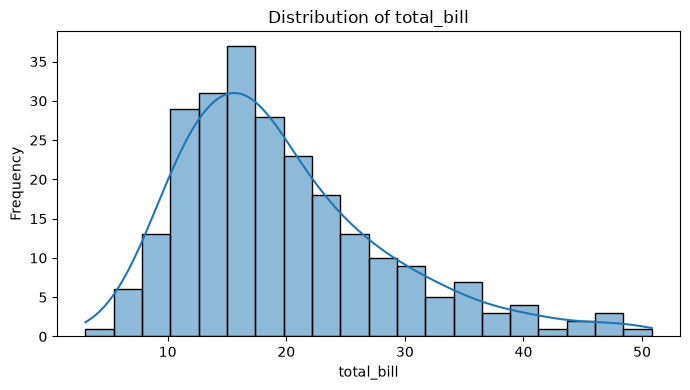

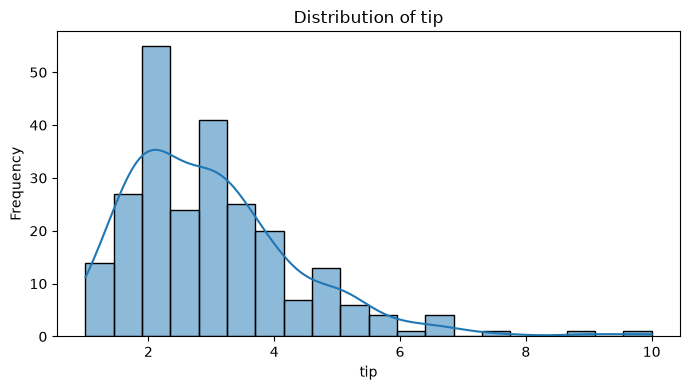

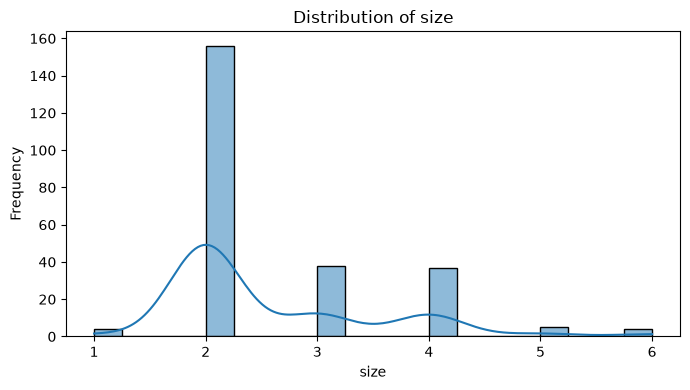

In [6]:
for column in numerical_df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=column, kde=True, bins=20)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 4. Kurtosis

Kurtosis measures the heaviness of a distribution's tails and its tendency to produce extreme observations.

- **Positive excess kurtosis:** Heavier tails than a normal distribution.
- **Negative excess kurtosis:** Lighter tails than a normal distribution.
- **Excess kurtosis near zero:** Similar tail behavior to a normal distribution.

Kurtosis should be interpreted alongside a histogram and other descriptive statistics.

In [7]:
kurtosis_values = numerical_df.kurtosis()

print("Excess kurtosis of numerical features:")
display(kurtosis_values.to_frame(name="Kurtosis").round(3))

Excess kurtosis of numerical features:


,Kurtosis
total_bill,1.218
tip,3.648
size,1.732


## 5. Types of Distribution Shapes

**Symmetric distribution:** The left and right sides are approximately balanced around the center.

**Left-skewed distribution:** The distribution has a longer tail toward smaller values. It often has mean less than median.

**Right-skewed distribution:** The distribution has a longer tail toward larger values. It often has mean greater than median.

These are general patterns. Use histograms and summary statistics together to interpret the actual data.

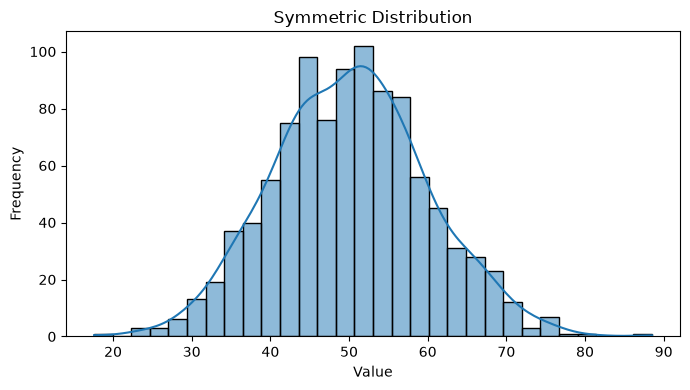

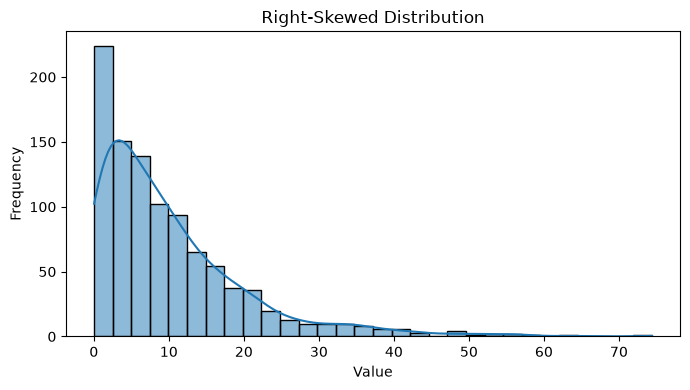

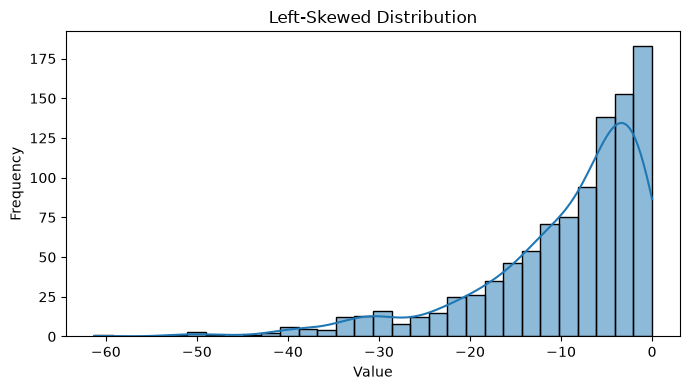

In [8]:
np.random.seed(42)

symmetric_data = np.random.normal(loc=50, scale=10, size=1000)
right_skewed_data = np.random.exponential(scale=10, size=1000)
left_skewed_data = -np.random.exponential(scale=10, size=1000)

examples = {
    "Symmetric Distribution": symmetric_data,
    "Right-Skewed Distribution": right_skewed_data,
    "Left-Skewed Distribution": left_skewed_data
}

for title, values in examples.items():
    plt.figure(figsize=(7, 4))
    sns.histplot(values, bins=30, kde=True)
    plt.title(title)
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [9]:
summary = numerical_df.describe().T

summary["Skewness"] = numerical_df.skew()
summary["Kurtosis"] = numerical_df.kurtosis()

# Count potential outliers using the IQR rule
outlier_counts = {}

for column in numerical_df.columns:
    q1 = numerical_df[column].quantile(0.25)
    q3 = numerical_df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_counts[column] = (
        (numerical_df[column] < lower) |
        (numerical_df[column] > upper)
    ).sum()

summary["Potential Outliers (IQR)"] = pd.Series(outlier_counts)

display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis,Potential Outliers (IQR)
total_bill,244.0,19.786,8.902,3.07,13.348,17.795,24.127,50.81,1.133,1.218,9
tip,244.0,2.998,1.384,1.00,2.000,2.900,3.562,10.00,1.465,3.648,9
size,244.0,2.570,0.951,1.00,2.000,2.000,3.000,6.00,1.448,1.732,9


## Conclusion

In this notebook, I analyzed numerical feature distributions using histograms and density curves. I explored normal and uniform distributions, examined skewness and kurtosis, and compared symmetric, left-skewed, and right-skewed distribution shapes. I also summarized the center and spread of numerical features and identified potential outliers using the IQR method.

Distribution analysis helps reveal patterns, asymmetry, variability, and unusual observations. The results should be interpreted in context before deciding whether data transformation or further investigation is needed.